In [1]:
# 在新 kernel 中从头运行。使用本次验证的源码快照。
import os
import sys
from pathlib import Path
from datetime import datetime
import json

WORKSPACE = Path('/mnt/public5/panguanyu/cross_species/scripts')
SOURCE = Path('/mnt/public5/panguanyu/cross_species/scripts/experiments/mosp_repeatability/20261022_160829/source')
SEED = 449640641#3315060519#2425102128#1602541748#410515491#3865204785#449640641#16818030105712371645
GPU = "2"  # 按当前空闲情况修改；本次验证使用同型号 4090。
if "torch" in sys.modules and sys.modules["torch"].cuda.is_initialized():
    if os.environ.get("CUBLAS_WORKSPACE_CONFIG") != ":4096:8":
        raise RuntimeError("请先重启 kernel：CUBLAS_WORKSPACE_CONFIG 必须在 CUDA 初始化前设置。")
for name, module in tuple(sys.modules.items()):
    if name == "Henosis" or name.startswith("Henosis."):
        location = getattr(module, "__file__", None)
        if location and not Path(location).resolve().is_relative_to(SOURCE):
            raise RuntimeError("请先重启 kernel，避免混用当前 Henosis 与已验证的源码快照。")
os.environ["CUDA_VISIBLE_DEVICES"] = GPU
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
for key in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[key] = "4"
os.environ["NUMBA_NUM_THREADS"] = "1"
sys.path.insert(0, str(SOURCE))

import torch
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

RUN_DIR = WORKSPACE / "saved_good_runs" / ("mosp_deterministic_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / "source_manifest.json").write_text((SOURCE.parent / "source_manifest.json").read_text())
(RUN_DIR / "config.json").write_text(json.dumps(dict(seed=SEED, gpu=GPU, torch=str(torch.__version__),
    cuda=torch.version.cuda, source=str(SOURCE), deterministic=True), indent=2))
print("本次输出：", RUN_DIR)


本次输出： /mnt/public5/panguanyu/cross_species/scripts/saved_good_runs/mosp_deterministic_20261024_090511_320766


In [2]:
import os


import scanpy as sc
import seaborn as sns
from tqdm import tqdm
import scanpy.external as sce

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler
from pytorch_metric_learning import miners, losses

from Henosis.dataprocess.h5a import H5ADTokenizer
from Henosis.const import set_species_context
from Henosis import data
import Henosis.resa as resa
import Henosis.utils as utils
import Henosis.mmd as mmd
import Henosis.lr_schedule as lr_sche
import Henosis.swav as swav
import Henosis.peak_student as peak_student
import Henosis.henosis as henosis
#torch.manual_seed(16818030105712371645)
import random
import numpy as np
random.seed(SEED)
np.random.seed(SEED % (2**32))
torch.manual_seed(SEED)  # Torch 保留完整 64 位 seed。


In [3]:
organ='motc'
embed_org='motc'

In [4]:
species_list=[
    'homo_sapiens_M1donor_rna','homo_sapiens_M1donor2_rna',
    'Macaca_mulatta_M1Dheni_atac','Macaca_mulatta_M1mac3_atac',
]

In [5]:
species_to_adata={
    k:sc.read_h5ad(f'/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/{k}.h5ad') for k in species_list
}

In [6]:
species_to_embed_file={
    'homo_sapiens_M1donor_rna':"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/atac_ntv3_pre/homo_sapiens_M1donor_rna.avg.embeddings",
    'homo_sapiens_M1donor2_rna':"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/atac_ntv3_pre/homo_sapiens_M1donor2_rna.avg.embeddings",
    'Macaca_mulatta_M1Dheni_atac':"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/motc/Macaca_mulatta_M1Dheni_atac_atac.ntv3_pre.layer18.peak.embeddings",
    'Macaca_mulatta_M1mac3_atac':"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/motc/Macaca_mulatta_M1mac3_atac_atac.ntv3_pre.layer18.peak.embeddings"
}

In [7]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v: k for k, v in species_dict.items()}

In [ ]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()
species_to_reps = {
    "homo_sapiens_M1donor_rna": "X_pca",
    "homo_sapiens_M1donor2_rna":'X_pca',
    "Macaca_mulatta_M1Dheni_atac": "X_lsi",
    "Macaca_mulatta_M1mac3_atac":"X_lsi"
}
species_cell_columns={
    "homo_sapiens_M1donor_rna": "celltype",
    "homo_sapiens_M1donor2_rna":'celltype',
    "Macaca_mulatta_M1Dheni_atac": "celltype",
    "Macaca_mulatta_M1mac3_atac":"celltype"
}
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=256,
    species_to_reps=species_to_reps,
    batch_species=len(species_list),
    species_cell_columns=species_cell_columns,
    collate_fn=data.h5labelcollate_fn,
    num_workers=0,
)

100%|██████████| 9160/9160 [00:00<00:00, 19035.68it/s]


homo_sapiens_M1donor_rna: X_pca
homo_sapiens_M1donor2_rna: X_pca
Macaca_mulatta_M1Dheni_atac: X_lsi
Macaca_mulatta_M1mac3_atac: X_lsi


In [ ]:
embed_size=1536
d_model=120
latent_size=64
num_layers=1
#net=peak_student.BtacDDPSwAV(species_to_embed_file,d_model,embed_size,latent_size,num_layers,10000,1,modality="atac",species_mapping=species_dict)
net=henosis.Henosis(species_to_embed_file,d_model,embed_size,latent_size,encoder_type='set',species_mapping=species_dict)

PCA ing
PCA done


In [10]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        input_ids,adata,sp,label=batch
        input_ids = input_ids.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)
        label=label.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scales=net(adata,input_ids,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                protein_features_i=torch.index_select(protein_features, 0, indices)

                sl += loss_fn(protein_features_i, gene_features_i,logit_scales[int(s)])
            
            #ml=loss_fn1(protein_features,sp)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=1.0,warm_epoch=2):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    (RUN_DIR / "training_config.json").write_text(json.dumps({
        "epochs": epochs, "lr": lr, "temp": temp,
        "ml_weight": ml_weight, "warm_epoch": warm_epoch,
    }, indent=2))
    torch.save(net.state_dict(), RUN_DIR / "initial_weights.pt")
    torch.save({"torch_cpu_rng": torch.get_rng_state(),
                "torch_cuda_rng": torch.cuda.get_rng_state_all(),
                "numpy_rng": np.random.get_state(), "python_rng": random.getstate()},
               RUN_DIR / "rng_before_training.pt")
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=swav.MultiScaleATACKNNLoss()#swav.SwAVLoss()#swav.WeightedMultiScaleATACKNNLoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            for species in species_dict:
                print(species,net.logit_scales[species].cpu().detach().numpy())
            
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [11]:
net_path = str(RUN_DIR / "training_checkpoint.pt")
species_to_h5=tokenized
epochs=40
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.0,ml_weight=1.0,warm_epoch=2)

init done
training on cuda
epoch:0,
Temp: 0.0


loss:12.8440,sl:12.84395790,ml:2.51688528,lr:0.00065681: 100%|██████████| 175/175 [00:23<00:00,  7.33it/s]


lr:0.0006568125000000001,
{'loss': 14.357911747523717, 'sl': 14.357911747523717, 'ml': 2.6993887874058315}
homo_sapiens_M1donor_rna 2.6825943
homo_sapiens_M1donor2_rna 2.6856039
Macaca_mulatta_M1Dheni_atac 2.644639
Macaca_mulatta_M1mac3_atac 2.685833
epoch:1,
Temp: 0.0


loss:11.8435,sl:11.84347725,ml:1.71426582,lr:0.00131262: 100%|██████████| 175/175 [00:22<00:00,  7.67it/s]


lr:0.001312625,
{'loss': 12.492289499555316, 'sl': 12.492289499555316, 'ml': 2.0452212265559604}
homo_sapiens_M1donor_rna 2.6850674
homo_sapiens_M1donor2_rna 2.7175128
Macaca_mulatta_M1Dheni_atac 2.5850592
Macaca_mulatta_M1mac3_atac 2.7652383
epoch:2,
Temp: 0.0


...

lr:0.00030493028419225927,
{'loss': 10.361547208513532, 'sl': 10.214070172991072, 'ml': 0.14747705246720996}
homo_sapiens_M1donor_rna 2.699908
homo_sapiens_M1donor2_rna 2.7474332
Macaca_mulatta_M1Dheni_atac 1.9500113
Macaca_mulatta_M1mac3_atac 2.373957
EarlyStopping counter: 3 out of 10
epoch:38,
Temp: 0.0


loss:10.4920,sl:10.31334400,ml:0.17865574,lr:0.00027096: 100%|██████████| 175/175 [00:22<00:00,  7.66it/s]


lr:0.00027095677120779347,
{'loss': 10.296261313302177, 'sl': 10.15231141771589, 'ml': 0.14394991027457374}
homo_sapiens_M1donor_rna 2.6940084
homo_sapiens_M1donor2_rna 2.7350097
Macaca_mulatta_M1Dheni_atac 1.9455279
Macaca_mulatta_M1mac3_atac 2.3747168
EarlyStopping counter: 4 out of 10
epoch:39,
Temp: 0.0


loss:10.6988,sl:10.51514053,ml:0.18367927,lr:0.00022430: 100%|██████████| 175/175 [00:23<00:00,  7.45it/s]

lr:0.00022430337432696198,
{'loss': 10.301419143676759, 'sl': 10.156734875270299, 'ml': 0.14468425112111227}
homo_sapiens_M1donor_rna 2.6808755
homo_sapiens_M1donor2_rna 2.7285392
Macaca_mulatta_M1Dheni_atac 1.9446352
Macaca_mulatta_M1mac3_atac 2.3725648
EarlyStopping counter: 5 out of 10
saving weight in /mnt/public5/panguanyu/cross_species/scripts/saved_good_runs/mosp_deterministic_20261024_090511_320766/training_checkpoint.pt


infering: 100%|██████████| 118/118 [00:03<00:00, 31.84it/s]


computing PCA
    with n_comps=25


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/hle_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


    finished (0:00:00)
Running MOT_Correction by 'species' -> adata.obsm['X_mot']
X_mot shape: (29971, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/hle_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:46)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:23)


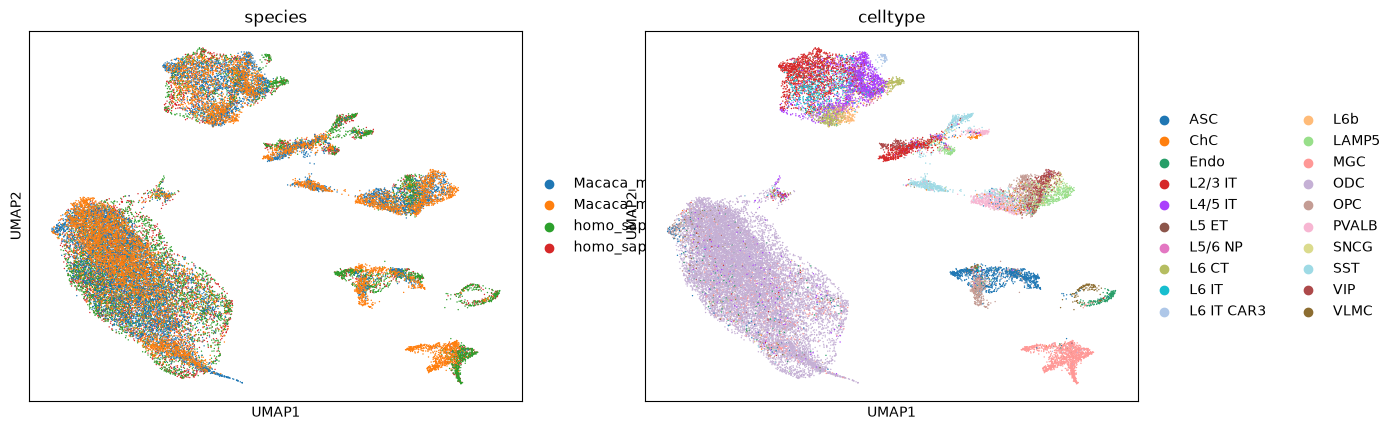

In [12]:
from Henosis.evaluate import evaluate_integration
from threadpoolctl import threadpool_limits

evaluation_config = dict(
    metadata_columns=["celltype"], embedding="protein", n_pcs=25,
    use_mot_correction=True, correction_by="species",
    correction_kwargs=dict(max_rounds=10, n_clusters=100, assignment_mode="sinkhorn", random_state=0),
    n_neighbors=15, umap_min_dist=0.3, umap_colors=["species", "celltype"],
)
(RUN_DIR / "evaluation_config.json").write_text(json.dumps(evaluation_config, indent=2))
with threadpool_limits(limits=1):
    integrated_adata = evaluate_integration(net, test_loader, species_to_adata=tokenized, **evaluation_config)


In [13]:
#integrated_adata.write('/mnt/public5/panguanyu/cross_species/gefor/code/h5a/mosp_449640641.h5ad')

In [14]:
from collections import defaultdict
import pandas as pd
def attention_score_topk_freq(
    net,
    dataset,
    indices,
    device,
    species_to_embed_file,
    chosen_species,
    csv_path,
    top_k=10,
    top_n=10,
):
    net.eval()
    net.to(device)

    gene_freq = defaultdict(int)

    net.transformer.embed.gene_id(species_to_embed_file)
    raw_map = net.transformer.embed.species_gene_id_map[chosen_species]
    token_to_gene_name = {v: k for k, v in raw_map.items()}

    with torch.no_grad():
        for i in tqdm(indices):

            input_ids = dataset[i]['input_ids'].unsqueeze(0).to(device)
            sp = dataset[i]['sp'].unsqueeze(0).to(device)

            with autocast('cuda'):
                attn_score = net.transformer.attn_score(input_ids, sp)

            attn_score = attn_score.cpu().numpy()[0]   # [L, L]
            input_tokens = input_ids.cpu().numpy()[0]       # [L]

            # column importance: [L]
            cell_gene_importance = attn_score.mean(axis=0)

            # top-k indices
            topk_idx = np.argsort(cell_gene_importance)[-top_k:][::-1]

            for idx in topk_idx:
                token_id = input_tokens[idx]
                if token_id <= 3:
                    continue

                gene_name = token_to_gene_name.get(token_id, f"Unknown_{token_id}")
                gene_freq[gene_name] += 1

    # normalize to frequency
    n_cells = len(indices)
    final_scores = {
        gene: freq / n_cells
        for gene, freq in gene_freq.items()
    }

    sorted_genes = sorted(final_scores.items(), key=lambda x: x[1], reverse=True)

    #top_n = 10
    '''print(f"\nTop {top_n} Genes by Top-{top_k} Attention Frequency:")

    top_genes=[]
    for rank, (gene, score) in enumerate(sorted_genes[:top_n]):
        print(f"Rank {rank+1}: {gene} (Freq: {score:.4f})")
        top_genes.append(gene)
    
    print(top_genes)'''
    
    df = pd.DataFrame(sorted_genes, columns=["gene", "score"])
    df.to_csv(csv_path, index=False)

    return sorted_genes[:top_n]

In [ ]:
'''import re
cell_type_column = 'celltype'
output_dir = '/mnt/public5/panguanyu/cross_species/gefor/code/tfc'
top_k = 1000
top_n = 20
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(output_dir, exist_ok=True)

all_top_results = []
result_manifest = []

chosen_cell_types=['MGC','ASC','ODC']

for chosen_species, adata in tokenized.items():
    if cell_type_column not in adata.obs.columns:
        print(f'Skip {chosen_species}: obs 中没有 {cell_type_column!r} 列')
        continue

    x_rep = species_to_reps.get(chosen_species, 'X_pca')
    dataset = data.AnndataFastDataset(adata, chosen_species, X_rep=x_rep)
    cell_type_to_indices = defaultdict(list)
    for cell_index, cell_type in enumerate(adata.obs[cell_type_column].tolist()):
        if pd.notna(cell_type):
            cell_type_to_indices[str(cell_type)].append(cell_index)

    for cell_type, indices in tqdm(
        cell_type_to_indices.items(),
        total=len(cell_type_to_indices),
        desc=f'{chosen_species} cell types',
    ):
        if cell_type not in chosen_cell_types:
            continue

        safe_cell_type = re.sub(r'[^0-9A-Za-z._-]+', '_', cell_type).strip('_')
        safe_cell_type = safe_cell_type or 'unnamed'
        csv_path = os.path.join(
            output_dir,
            f'{organ}_{chosen_species}_{safe_cell_type}.csv',
        )

        top_results = attention_score_topk_freq(
            net,
            dataset,
            indices,
            device,
            species_to_embed_file,
            chosen_species,
            csv_path,
            top_k=top_k,
            top_n=top_n,
        )

        result_manifest.append({
            'species': chosen_species,
            'cell_type': cell_type,
            'n_cells': len(indices),
            'csv_path': csv_path,
        })
        all_top_results.extend(
            {
                'species': chosen_species,
                'cell_type': cell_type,
                'rank': rank,
                'gene': gene,
                'score': score,
                'n_cells': len(indices),
            }
            for rank, (gene, score) in enumerate(top_results, start=1)
        )

manifest_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_manifest.csv')
summary_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_top{top_n}.csv')
pd.DataFrame(result_manifest).to_csv(manifest_path, index=False)
pd.DataFrame(all_top_results).to_csv(summary_path, index=False)
print(f'完成 {len(result_manifest)} 个物种-细胞类型组合')
print(f'清单已保存到: {manifest_path}')
print(f'Top-{top_n} 汇总已保存到: {summary_path}')
pd.DataFrame(result_manifest)'''

homo_sapiens_M1donor_rna cell types:   0%|          | 0/20 [00:00<?, ?it/s]

homo_sapiens_M1donor2_rna cell types:   0%|          | 0/20 [00:05<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
pd.DataFrame(result_manifest)['csv_path'].tolist()

['/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_ODC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_ASC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_MGC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor2_rna_ODC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor2_rna_ASC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor2_rna_MGC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_Macaca_mulatta_M1Dheni_atac_ODC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_Macaca_mulatta_M1Dheni_atac_MGC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_Macaca_mulatta_M1Dheni_atac_ASC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_Macaca_mulatta_M1mac3_atac_ODC.csv',
 '/mnt/public5/panguanyu/cross_species/gefor/c

In [ ]:
result_manifest

[{'species': 'homo_sapiens_M1donor_rna',
  'cell_type': 'ODC',
  'n_cells': 2721,
  'csv_path': '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_ODC.csv'},
 {'species': 'homo_sapiens_M1donor_rna',
  'cell_type': 'ASC',
  'n_cells': 224,
  'csv_path': '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_ASC.csv'},
 {'species': 'homo_sapiens_M1donor_rna',
  'cell_type': 'MGC',
  'n_cells': 211,
  'csv_path': '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor_rna_MGC.csv'},
 {'species': 'homo_sapiens_M1donor2_rna',
  'cell_type': 'ODC',
  'n_cells': 3794,
  'csv_path': '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor2_rna_ODC.csv'},
 {'species': 'homo_sapiens_M1donor2_rna',
  'cell_type': 'ASC',
  'n_cells': 520,
  'csv_path': '/mnt/public5/panguanyu/cross_species/gefor/code/tfc/motc_homo_sapiens_M1donor2_rna_ASC.csv'},
 {'species': 'homo_sapiens_M1donor2_rna',
  'cell